In [1]:
import plumed
import matplotlib.pyplot as plt
import numpy as np
import subprocess
import os

In [15]:
#gmx trjcat -f ../*.xtc -o plumed_1_49.xtc
#gmx trjconv -f plumed_1_49.xtc -s ../../inputs/aac1_500ns_notrr.tpr -pbc mol -center
#gmx trjconv -f trajout.xtc -s ../../inputs/aac1_500ns_notrr.tpr -o plumed_1_49i_mol_fit.xtc -fit rot+trans -center

In [ ]:


#summing hills
#cat HILLS.0 HILLS.1 HILLS.2 HILLS.3 HILLS.4 HILLS.5 HILLS.6 HILLS.7 HILLS.8 | sort -n > HILLS.040725

#plumed sum_hills --hills HILLS --mintozero 

In [ ]:
#unit conversion for correct axis label (and some amusing copilot suggestions)
e_charge = 1.602176634e-19 # C #copilot knew the value once I typed in the variable name and it matches https://physics.nist.gov/cgi-bin/cuu/Value?e

#Below I typed in the variable name and copilot suggested the rest of the following line, 
# which is only slightly wrong, having seemingly learned from my comment on the previous line:
#epsilon0 = 8.854187817e-12 # F/m #copilot suggested this and it matches https://physics.nist.gov/cgi-bin/cuu/Value?epsilon0
#Below is copilot trying to impersonate me and talking about itself in the 3rd person. As I wrote the previous sentence, copilot suggested that I end it with: ", which is a bit creepy but also kind of funny"
#epsilon0 = 8.8541878188e-12 # F/m # I found this value in the documentation for scipy.constants, which is a more recent value than the one suggested by copilot

epsilon0 = 8.8541878188e-12 # F/m = C^2/J # from https://physics.nist.gov/cgi-bin/cuu/Value?ep0

#copilot suggested the correct value, units, constant name, and source here
kB = 1.380649e-23 # J/K # Boltzmann constant, from https://physics.nist.gov/cgi-bin/cuu/Value?k
#copilot got this one except for the link having NA capitalized
NA = 6.02214076e23 # Avogadro's number, from https://physics.nist.gov/cgi-bin/cuu/Value?na

T = 310.15 #simulation temperature

D=80 #dielectric constant of water

#conversion factor (from sum of inverse distances in nm to energies in kT)
conversion_factor = e_charge**2 / (D * 4 * np.pi * epsilon0 * kB * T * 1e-9) # in kJ/mol, equation suggested by copilot and matches my derivation except for the nm to m conversion term which it missed
conversion_factor_kJmol = NA*e_charge**2 / (D * 4 * np.pi * epsilon0 * kB * T * 1e-9*1000) # in kJ/mol, equation suggested by copilot and matches my derivation except for the nm to m conversion term which it missed
#note that this is the absolute electrostatic binding energy in vacuum, not the energy relative to aqueous solution

#beware that this is a bit misleading, since the contour levels are in kJ/mol but the x-axis label is in kT.
#The above comment was written by copilot after I said 'beware', and it was a useful point that I hadn't thought of


#-------------------------------------------------------------------------------------------------------------
#see https://www.plumed-tutorials.org/lessons/21/004/data/notebooks/solution.html

#generate fes.dat from HILLS on a dev node with with: plumed sum_hills --hills HILLS --mintozero 
system = 4
runnum = 2
date = "042125"
fesfile = f"/home/jonathan/Documents/grabelab/aac1-ucp1/aac1/trajectories/plumed_tests/plumed/sys{system}/mwm{runnum}/fes-{date}.dat"
#fesfile = f"/home/jonathan/Documents/grabelab/aac1-ucp1/aac1/trajectories/plumed_tests/plumed/run1/run/fes-033125.dat"

# plot final fes
data=plumed.read_as_pandas(fesfile)

nbins_pc_p = int(data.__dict__['plumed_constants'][2][2])
nbins_pc_f = int(data.__dict__['plumed_constants'][6][2])

# get data for countour plot
pc_p = np.array(data["pc_f1b"]).reshape(nbins_pc_f,nbins_pc_p)#*conversion_factor
pc_f = np.array(data["pc_f2b"]).reshape(nbins_pc_f,nbins_pc_p)
fes = np.array(data["file.free"]).reshape(nbins_pc_f,nbins_pc_p)*1000/(NA*kB*T)

#plot
from matplotlib import ticker, cm

max_contour = 300

plt.contour(pc_p, pc_f, fes, levels=range(0,max_contour,15), linewidths=0.5, colors='k')
cntr = plt.contourf(pc_p, pc_f, fes, levels=range(0,max_contour), cmap=cm.jet)
plt.colorbar(cntr, label="FES [kT]")

#plt.colorbar(cntr, label="FES [kJ/mol]")

plt.xlim(-.3,.3) #-25,0
plt.ylim(0.25,3)
plt.xlabel("delta-dRMSD")
plt.ylabel("sigma-dRMSD")
4-fluorosilane
#plt.savefig(f"run1-run-fes-{date}.png", dpi=600)

+++ Loading the PLUMED kernel runtime +++
+++ PLUMED_KERNEL="/home/jonathan/anaconda3/envs/plumed1/lib/libplumedKernel.so" +++
/tmp/ipykernel_208061/4148381582.py:41: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data=plumed.read_as_pandas(fesfile)


KeyError: 'pc_f1b'

+++ Loading the PLUMED kernel runtime +++
+++ PLUMED_KERNEL="/home/jonathan/anaconda3/envs/plumed1/lib/libplumedKernel.so" +++
/tmp/ipykernel_208061/3220861234.py:7: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  colvar=plumed.read_as_pandas(infile)
+++ Loading the PLUMED kernel runtime +++
+++ PLUMED_KERNEL="/home/jonathan/anaconda3/envs/plumed1/lib/libplumedKernel.so" +++
/tmp/ipykernel_208061/3220861234.py:7: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  colvar=plumed.read_as_pandas(infile)
+++ Loading the PLUMED kernel runtime +++
+++ PLUMED_KERNEL="/home/jonathan/anaconda3/envs/plumed1/lib/libplumedKernel.so" +++
/tmp/ipykernel_208061/3220861234.py:7: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instea

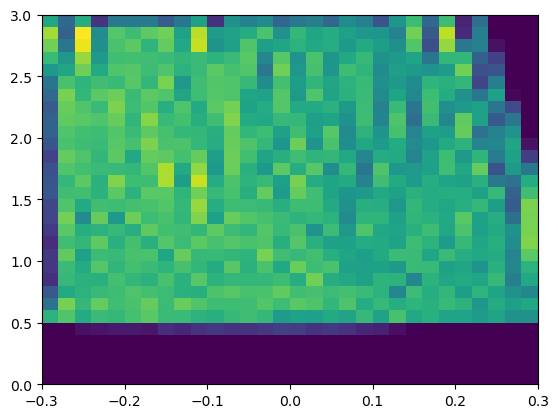

In [35]:

cv_1 = []
cv_2 = []

for walker in range(0,24):

    infile = f"/home/jonathan/Documents/grabelab/aac1-ucp1/aac1/trajectories/plumed_tests/plumed/sys{system}/mwm{runnum}/{walker}/COLVAR"
    colvar=plumed.read_as_pandas(infile)


    cv_1 += list(colvar.pc_f1)
    cv_2 += list(colvar.pc_f2)

h = plt.hist2d(cv_1, cv_2, range=[[-0.3,0.3],[0,3]], bins=[30,30])

In [45]:
#walker = 1
for walker in range(0,24):
    infile = f"/home/jonathan/Documents/grabelab/aac1-ucp1/aac1/trajectories/plumed_tests/plumed/sys{system}/mwm{runnum}/{walker}/COLVAR"
    colvar=plumed.read_as_pandas(infile)

    print("--------------------------------------------------------")
    print(walker)
    freq = 100

    delta = list(colvar.pc_f1[::freq])
    sigma = list(colvar.pc_f2[::freq])

    pc_c = [(i+j)/2 for i,j in zip(delta,sigma)]
    pc_m = [-(i-j)/2 for i,j in zip(delta,sigma)]

    plt.plot(delta, sigma)
    plt.xlabel("flipping")
    plt.ylabel("unfolding")
    # plt.xlim(0,3)
    # plt.ylim(0,3)

    #plt.axis("equal")

    plt.xlim(-0.31, 0.31)
    plt.ylim(0.5, 2)
    plt.show()

+++ Loading the PLUMED kernel runtime +++
+++ PLUMED_KERNEL="/home/jonathan/anaconda3/envs/plumed1/lib/libplumedKernel.so" +++


FileNotFoundError: [Errno 2] No such file or directory: '/home/jonathan/Documents/grabelab/aac1-ucp1/aac1/trajectories/plumed_tests/plumed/sys3/mwm1/0/COLVAR'

+++ Loading the PLUMED kernel runtime +++
+++ PLUMED_KERNEL="/home/jonathan/anaconda3/envs/plumed1/lib/libplumedKernel.so" +++
/tmp/ipykernel_208061/376968774.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  colvar=plumed.read_as_pandas(infile)


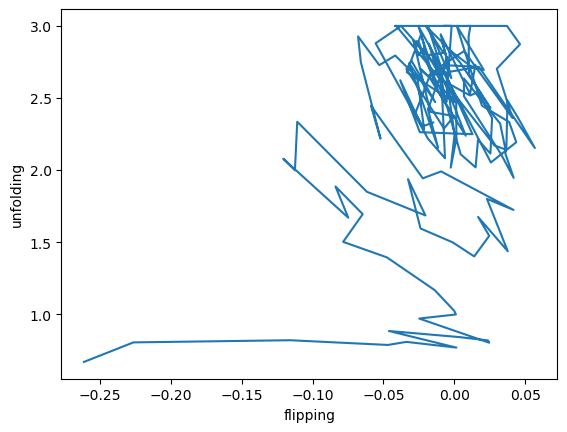

In [15]:

walker = 1
infile = f"/home/jonathan/Documents/grabelab/aac1-ucp1/aac1/trajectories/plumed_tests/plumed/sys{system}/mwm{runnum}/{walker}/COLVAR"
colvar=plumed.read_as_pandas(infile)
# plt.plot(colvar.time,colvar.pc_f1b,label="pc_f1b")
# plt.xlabel("time")
# plt.ylabel("flipping")
# plt.legend()
# plt.show()

# plt.plot(colvar.time,colvar.pc_f2b,label="pc_f2b")
# plt.xlabel("time")
# plt.ylabel("unfolding")
# plt.legend()
# plt.show()

#plt.scatter(colvar.pc_f, colvar.pc_p, marker=",")

freq = 100
plt.plot(colvar.pc_f1b[::freq], colvar.pc_f2b[::freq])
plt.xlabel("flipping")
plt.ylabel("unfolding")
#plt.xlim((-np.pi,np.pi))
#plt.ylim((-np.pi,np.pi))
plt.show()



+++ Loading the PLUMED kernel runtime +++
+++ PLUMED_KERNEL="/home/jonathan/anaconda3/envs/plumed1/lib/libplumedKernel.so" +++
/tmp/ipykernel_208061/432651642.py:43: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data=plumed.read_as_pandas(fesfile)


Text(0, 0.5, '(dRMSDc-dRMSDm)/(dRMSDc+dRMSDm)')

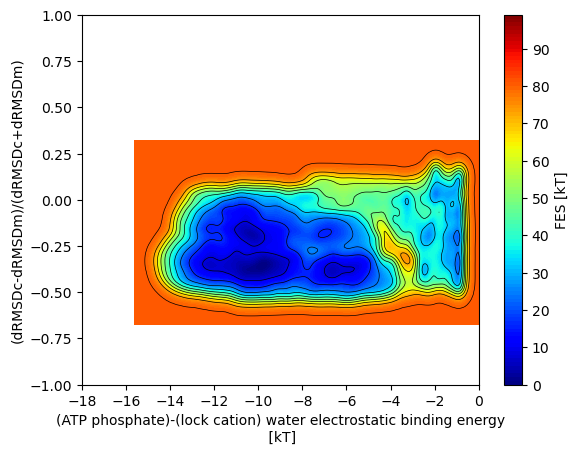

In [ ]:
#unit conversion for correct axis label (and some amusing copilot suggestions)
e_charge = 1.602176634e-19 # C #copilot knew the value once I typed in the variable name and it matches https://physics.nist.gov/cgi-bin/cuu/Value?e

#Below I typed in the variable name and copilot suggested the rest of the following line, which is only slightly wrong, having seemingly learned from my comment on the previous line:
#epsilon0 = 8.854187817e-12 # F/m #copilot suggested this and it matches https://physics.nist.gov/cgi-bin/cuu/Value?epsilon0
#Below is copilot trying to impersonate me and talking about itself in the 3rd person. As I wrote the previous sentence, copilot suggested that I end it with: ", which is a bit creepy but also kind of funny"
#epsilon0 = 8.8541878188e-12 # F/m # I found this value in the documentation for scipy.constants, which is a more recent value than the one suggested by copilot

epsilon0 = 8.8541878188e-12 # F/m = C^2/J # from https://physics.nist.gov/cgi-bin/cuu/Value?ep0

#copilot suggested the correct value, units, constant name, and source here
kB = 1.380649e-23 # J/K # Boltzmann constant, from https://physics.nist.gov/cgi-bin/cuu/Value?k
#copilot got this one except for the link having NA capitalized
NA = 6.02214076e23 # Avogadro's number, from https://physics.nist.gov/cgi-bin/cuu/Value?na

T = 310.15 #simulation temperature

D=80 #dielectric constant of water

#conversion factor (from sum of inverse distances in nm to energies in kT)
conversion_factor = e_charge**2 / (D * 4 * np.pi * epsilon0 * kB * T * 1e-9) # in kJ/mol, equation suggested by copilot and matches my derivation except for the nm to m conversion term which it missed
conversion_factor_kJmol = NA*e_charge**2 / (D * 4 * np.pi * epsilon0 * kB * T * 1e-9*1000) # in kJ/mol, equation suggested by copilot and matches my derivation except for the nm to m conversion term which it missed
#note that this is the absolute electrostatic binding energy in vacuum, not the energy relative to aqueous solution

#beware that this is a bit misleading, since the contour levels are in kJ/mol but the x-axis label is in kT.
#The above comment was written by copilot after I said 'beware', and it was a useful point that I hadn't thought of


#-------------------------------------------------------------------------------------------------------------
#see https://www.plumed-tutorials.org/lessons/21/004/data/notebooks/solution.html

#generate fes.dat from HILLS on a dev node with with: plumed sum_hills --hills HILLS --mintozero 

system = 3
runnum = 1
date = "041625"
fesfile = f"/home/jonathan/Documents/grabelab/aac1-ucp1/aac1/trajectories/plumed_tests/plumed/sys{system}/mwm{runnum}/fes-{date}.dat"
#fesfile = f"/home/jonathan/Documents/grabelab/aac1-ucp1/aac1/trajectories/plumed_tests/plumed/sys4/mwm{runnum}/fes-{date}.dat"
#fesfile = f"/home/jonathan/Documents/grabelab/aac1-ucp1/aac1/trajectories/plumed_tests/plumed/run1/run/fes-033125.dat"


# plot final fes
data=plumed.read_as_pandas(fesfile)

nbins_pc_p = int(data.__dict__['plumed_constants'][2][2])
nbins_pc_f = int(data.__dict__['plumed_constants'][6][2])

# get data for countour plot
pc_p = np.array(data["pc_p"]).reshape(nbins_pc_f,nbins_pc_p)*conversion_factor
pc_f = np.array(data["pc_f"]).reshape(nbins_pc_f,nbins_pc_p)
fes = np.array(data["file.free"]).reshape(nbins_pc_f,nbins_pc_p)*1000/(NA*kB*T)

#plot
from matplotlib import ticker, cm

max_contour = 100

plt.contour(pc_p, pc_f, fes, levels=range(0,max_contour,8), linewidths=0.5, colors='k')
cntr = plt.contourf(pc_p, pc_f, fes, levels=range(0,max_contour), cmap=cm.jet)
plt.colorbar(cntr, label="FES [kT]")

#plt.colorbar(cntr, label="FES [kJ/mol]")

plt.xlim(-18,0) #-25,0
plt.ylim(-1,1)
plt.xlabel(f"(ATP phosphate)-(lock cation) water electrostatic binding energy\n [kT]")
plt.ylabel("(dRMSDc-dRMSDm)/(dRMSDc+dRMSDm)")

#plt.savefig(f"run1-run-fes-{date}.png", dpi=600)

/tmp/ipykernel_145557/3594453186.py:2: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  plt.plot(colvar.pc_f[::100], colvar.pc_p[::100], "o", marker=",")


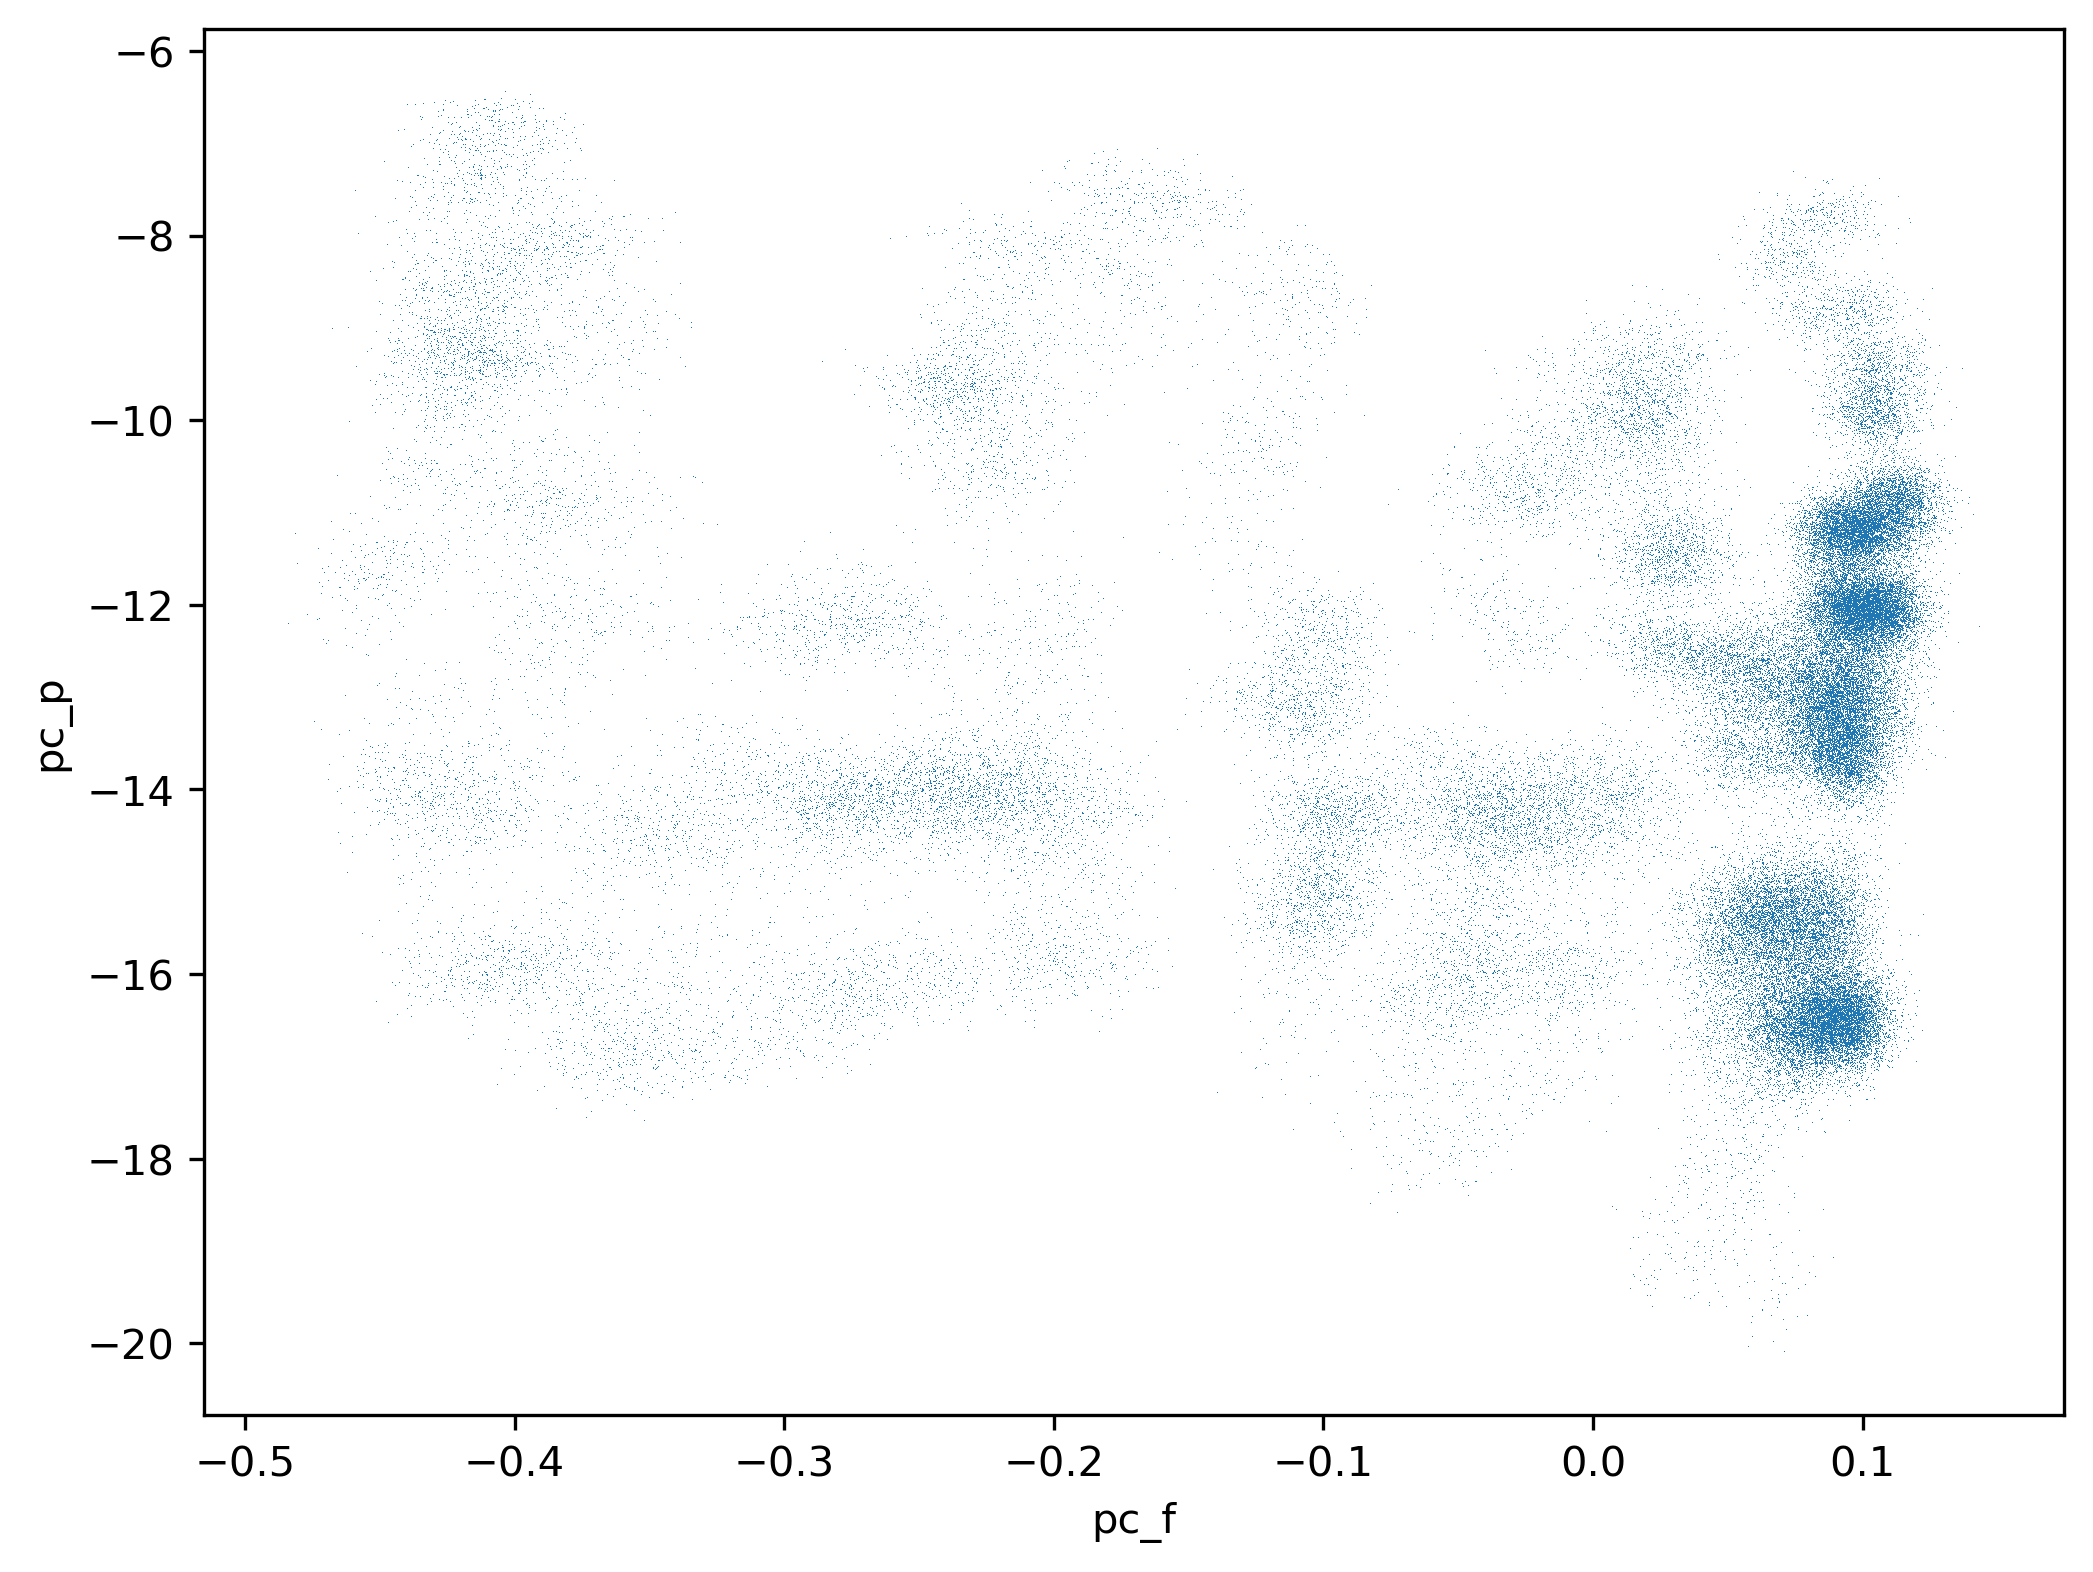

In [7]:
plt.figure(figsize=(8, 6), dpi=300) # Creates a figure with 300 DPI
plt.plot(colvar.pc_f[::100], colvar.pc_p[::100], "o", marker=",")
plt.xlabel("pc_f")
plt.ylabel("pc_p")
#plt.xlim((-np.pi,np.pi))
#plt.ylim((-np.pi,np.pi))
plt.show()

In [8]:
#pc_f drops to exactly 0 at 412108.52 and 421388.52 ps, probably due to a bug, 
# but I cannot tell from plumed.dat how such a bug could occur, 
# The protein does not cross the PBC when this happens, so it is not a PBC issue

# colv_f = [i for i in colvar.pc_f]

# for i, cf in enumerate(colv_f):
#     if cf == 0:
#         print(colvar.time[i])
#         #print(cf)

# print(2256*200)

In [9]:
#unit conversion for correct axis label (and some amusing copilot suggestions)
e_charge = 1.602176634e-19 # C #copilot knew the value once I typed in the variable name and it matches https://physics.nist.gov/cgi-bin/cuu/Value?e

#Below I typed in the variable name and copilot suggested the rest of the following line, 
# which is only slightly wrong, having seemingly learned from my comment on the previous line:
#epsilon0 = 8.854187817e-12 # F/m #copilot suggested this and it matches https://physics.nist.gov/cgi-bin/cuu/Value?epsilon0
#Below is copilot trying to impersonate me and talking about itself in the 3rd person. As I wrote the previous sentence, copilot suggested that I end it with: ", which is a bit creepy but also kind of funny"
#epsilon0 = 8.8541878188e-12 # F/m # I found this value in the documentation for scipy.constants, which is a more recent value than the one suggested by copilot

epsilon0 = 8.8541878188e-12 # F/m = C^2/J # from https://physics.nist.gov/cgi-bin/cuu/Value?ep0

#copilot suggested the correct value, units, constant name, and source here
kB = 1.380649e-23 # J/K # Boltzmann constant, from https://physics.nist.gov/cgi-bin/cuu/Value?k
#copilot got this one except for the link having NA capitalized
NA = 6.02214076e23 # Avogadro's number, from https://physics.nist.gov/cgi-bin/cuu/Value?na

T = 310.15 #simulation temperature

#conversion factor (from sum of inverse distances in nm to energies in kT)
conversion_factor = e_charge**2 / (4 * np.pi * epsilon0 * kB * T * 1e-9) # in kJ/mol, equation suggested by copilot and matches my derivation except for the nm to m conversion term which it missed
conversion_factor_kJmol = NA*e_charge**2 / (4 * np.pi * epsilon0 * kB * T * 1e-9*1000) # in kJ/mol, equation suggested by copilot and matches my derivation except for the nm to m conversion term which it missed
#note that this is the absolute electrostatic binding energy in vacuum, not the energy relative to aqueous solution

#beware that this is a bit misleading, since the contour levels are in kJ/mol but the x-axis label is in kT.
#The above comment was written by copilot after I said 'beware' and It's a useful point that I hadn't thought of


#-------------------------------------------------------------------------------------------------------------
#see https://www.plumed-tutorials.org/lessons/21/004/data/notebooks/solution.html

#generate fes.dat from HILLS on a dev node with with: plumed sum_hills --hills HILLS --mintozero 

fesfile = f"/home/jonathan/Documents/grabelab/aac1-ucp1/aac1/trajectories/plumed_tests/plumed/run1/{runfolder}/fes.dat" #-033125

# plot final fes
data=plumed.read_as_pandas(fesfile)

nbins_pc_p = int(data.__dict__['plumed_constants'][2][2])
nbins_pc_f = int(data.__dict__['plumed_constants'][6][2])

# get data for countour plot
pc_p = np.array(data["pc_p"]).reshape(nbins_pc_f,nbins_pc_p) #*conversion_factor
pc_f = np.array(data["pc_f"]).reshape(nbins_pc_f,nbins_pc_p)
fes = np.array(data["file.free"]).reshape(nbins_pc_f,nbins_pc_p)*1000/(NA*kB*T)


#plot
from matplotlib import ticker, cm

max_contour = 100

plt.contour(pc_p, pc_f, fes, levels=range(0,max_contour,8), linewidths=0.5, colors='k')
cntr = plt.contourf(pc_p, pc_f, fes, levels=range(0,max_contour), cmap=cm.jet)
plt.colorbar(cntr, label="FES [kT]")

#plt.colorbar(cntr, label="FES [kJ/mol]")

plt.xlim(-25,0)
plt.ylim(-1,1)
plt.xlabel(f"(ATP phosphate)-(lock cation) vacuum electrostatic binding energy\n (kT)")
plt.ylabel("(dRMSDc-dRMSDm)/(dRMSDc+dRMSDm)")



NameError: name 'runfolder' is not defined

In [ ]:
e_charge**2 / (4 * np.pi * epsilon0 * kB * T * 1e-9) * 1/.3

In [ ]:
print([i for i in data.__dict__][-1])
print(int(data.__dict__['plumed_constants'][2][2]))
print(int(data.__dict__['plumed_constants'][6][2]))


In [ ]:
# fes_phi=plumed.read_as_pandas("fes_phi.dat").replace([np.inf, -np.inf], np.nan).dropna()
# plt.plot(fes_phi.phi,fes_phi.ffphi)
# plt.xlim((-np.pi,np.pi))
# plt.xlabel("$\phi$")
# plt.ylabel("$F(\phi)$")
# plt.show()

# fes_psi=plumed.read_as_pandas("fes_psi.dat").replace([np.inf, -np.inf], np.nan).dropna()
# plt.plot(fes_psi.psi,fes_psi.ffpsi)
# plt.xlim((-np.pi,np.pi))
# plt.xlabel("$\psi$")
# plt.ylabel("$F(\psi)$")
# plt.show()

In [ ]:
import scipy
scipy.constants.epsilon_0

In [ ]:
1000/(NA*kB*T)